# 5-SED — Sound Event Detection (SED)
### Demo: Pretrained YAMNet per-frame scores -> threshold + smoothing -> timed events

### AIML ZG527: Audio Analysis
**Authored by:** Seetha Parameswaran, BITS Pilani WILP
### Learning Objectives
- Read YAMNet's per-frame scores instead of a clip embedding
- Convert frame scores to timed events via threshold + minimum-duration
- Evaluate with segment-based and event-based F1
---
### Setup and Import Libraries

**Task (SED):** detect **what** events occur **and when** (onset/offset). Multi-label,
frame-level, events may overlap. **No training** here — pure pretrained inference.

**Approach:** YAMNet scores each ~0.48 s frame over 521 AudioSet classes. We
(1) map our target events to AudioSet classes, (2) read the per-frame score for each target,
(3) smooth + threshold, (4) turn score runs into `(event, onset, offset)`.

**Same YAMNet backbone as 5-ESC / 5-ASC** — here we use its *frame-level* output instead of
a clip embedding. CPU only, nothing saved.

---
**Requirements:**
```
pip install tensorflow tensorflow_hub librosa resampy numpy scipy matplotlib pandas
```

---
### Dataset: synthetic soundscapes (Scaper)
Generated locally from UrbanSound8K — 10-second soundscapes
with strong onset/offset labels in `annotations.csv`. No large download.

In [1]:
import os, csv
import numpy as np
import pandas as pd
import librosa

os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"

import tensorflow_hub as hub
from scipy.signal import medfilt
import matplotlib.pyplot as plt
np.random.seed(0)

2026-07-01 19:15:50.123278: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2026-07-01 19:15:50.123302: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


## 1. Configuration
Assumed layout of the hosted subset (edit after downloading):
```
SED_ROOT/
  audio/            soundscape_01.wav ...
  annotations.csv   # columns: filename,onset,offset,event  (strong labels, seconds)
```
`TARGET_EVENTS` are your event names; `MAPPING` links each to AudioSet display-name
substrings YAMNet knows. Edit `MAPPING` to match your downloaded classes.

## 2. Load YAMNet + its class map
The class map gives the display name of each of the 521 AudioSet output classes.

In [2]:
yamnet = hub.load('https://tfhub.dev/google/yamnet/1')
class_map_path = yamnet.class_map_path().numpy().decode()
class_df = pd.read_csv(class_map_path)   # columns: index, mid, display_name
display_names = class_df['display_name'].tolist()
print('YAMNet loaded;', len(display_names), 'classes.')

2026-07-01 19:15:55.827913: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcuda.so.1'; dlerror: libcuda.so.1: cannot open shared object file: No such file or directory
2026-07-01 19:15:55.827943: W tensorflow/stream_executor/cuda/cuda_driver.cc:269] failed call to cuInit: UNKNOWN ERROR (303)
2026-07-01 19:15:55.827961: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:156] kernel driver does not appear to be running on this host (seetha-HP-348-G4): /proc/driver/nvidia/version does not exist
2026-07-01 19:15:55.828287: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


YAMNet loaded; 521 classes.


In [3]:
# >>> EDIT THESE after downloading <<<
SED_ROOT = '/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/sed_subset'
AUDIO_DIR  = os.path.join(SED_ROOT, 'audio')
ANNOT_CSV  = os.path.join(SED_ROOT, 'annotations.csv')

SR = 16000
HOP = 0.48                # YAMNet frame hop (seconds)
THRESHOLD = 0.10          # score threshold per target event 
                          # between the 0.10 (too loose) and 0.30 (too strict)
MEDIAN_K = 1              # median-filter window (frames, must be odd)
COLLAR = 0.5             # onset tolerance for event-based F1 (seconds)
MIN_DUR = 0.2             # seconds; ignore detections shorter than this


# friendly event name -> list of AudioSet display-name substrings to match
MAPPING = {
    'dog_bark':     ['Bark', 'Dog'],
    'car_horn':     ['Vehicle horn', 'Honk', 'Toot'],
    'siren':        ['Siren'],
    'gun_shot':     ['Gunshot, gunfire'],
    'jackhammer':   ['Jackhammer'],
    'drilling':     ['Drill'],
    'engine_idling':['Engine'],
    'children_playing':['Children', 'Child speech'],
    #'street_music': ['Music'],
}
TARGET_EVENTS = list(MAPPING.keys())

## 3. Resolve each target event to YAMNet class indices

In [4]:
def resolve_indices(substrings):
    idx = []
    for s in substrings:
        for i, name in enumerate(display_names):
            if s.lower() in name.lower():
                idx.append(i)
    return sorted(set(idx))

EVENT_IDX = {ev: resolve_indices(subs) for ev, subs in MAPPING.items()}
for ev, idx in EVENT_IDX.items():
    names = [display_names[i] for i in idx]
    print(f'{ev:<18} -> {names if names else "** NO MATCH - edit MAPPING **"}')

dog_bark           -> ['Dog', 'Bark', 'Whimper (dog)', 'Canidae, dogs, wolves']
car_horn           -> ['Honk', 'Vehicle horn, car horn, honking', 'Toot', 'Toothbrush', 'Electric toothbrush']
siren              -> ['Police car (siren)', 'Ambulance (siren)', 'Fire engine, fire truck (siren)', 'Siren', 'Civil defense siren']
gun_shot           -> ['Gunshot, gunfire']
jackhammer         -> ['Jackhammer']
drilling           -> ["Dental drill, dentist's drill", 'Drill']
engine_idling      -> ['Fire engine, fire truck (siren)', 'Aircraft engine', 'Jet engine', 'Engine', 'Light engine (high frequency)', 'Medium engine (mid frequency)', 'Heavy engine (low frequency)', 'Engine knocking', 'Engine starting']
children_playing   -> ['Child speech, kid speaking', 'Children shouting', 'Children playing', 'Music for children']


## 4. Per-frame scores and event extraction

In [5]:
def frame_scores(wav):
    if wav.size < SR:
        wav = np.pad(wav, (0, SR - wav.size))
    scores, _, _ = yamnet(wav.astype(np.float32))   # (frames, 521)
    return scores.numpy()

'''def target_series(scores, ev):
    idx = EVENT_IDX[ev]
    if not idx:
        return np.zeros(scores.shape[0])
    s = scores[:, idx].max(axis=1)          # strongest matching class per frame
    return medfilt(s, kernel_size=MEDIAN_K) # temporal smoothing'''

def target_series(scores, ev):
    idx = EVENT_IDX[ev]
    if not idx:
        return np.zeros(scores.shape[0])
    s = scores[:, idx].max(axis=1)
    k = min(MEDIAN_K, len(s))
    if k % 2 == 0:            # medfilt needs odd kernel
        k -= 1
    if k >= 3:
        s = medfilt(s, kernel_size=k)
    return s

def runs_to_events(mask, ev):
    events, n, i = [], len(mask), 0
    while i < n:
        if mask[i]:
            j = i
            while j < n and mask[j]:
                j += 1
            if (j - i) * HOP >= MIN_DUR:          # drop very short (spurious) detections
                events.append({'event': ev,
                               'onset':  round(i * HOP, 2),
                               'offset': round(j * HOP, 2)})
            i = j
        else:
            i += 1
    return events

def detect(wav):
    scores = frame_scores(wav)
    preds = []
    for ev in TARGET_EVENTS:
        series = target_series(scores, ev)
        preds += runs_to_events(series >= THRESHOLD, ev)
    return preds, scores

## 5. Run on one clip: score curves + events on the spectrogram

duration: 10.0 s   frames: 20
Detected events in soundscape_00.wav :
dog_bark         max=0.002
car_horn         max=0.006
siren            max=0.002
gun_shot         max=0.390
jackhammer       max=0.000
drilling         max=0.000
engine_idling    max=0.005
children_playing max=0.010


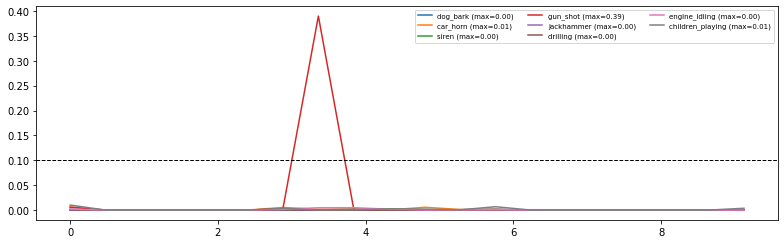

In [6]:
import glob
wav_files = sorted(glob.glob(os.path.join(AUDIO_DIR, '*.wav')))
assert wav_files, f'no wavs in {AUDIO_DIR} - fix paths'
demo_file = wav_files[0]
wav, _ = librosa.load(demo_file, sr=SR, mono=True)
print('duration:', len(wav)/SR, 's', '  frames:', frame_scores(wav).shape[0])
pred_events, scores = detect(wav)

print('Detected events in', os.path.basename(demo_file), ':')
for ev in TARGET_EVENTS:
    print(f"{ev:<16} max={target_series(scores, ev).max():.3f}")

# active (non-empty) target score curves
active = [ev for ev in TARGET_EVENTS if target_series(scores, ev).max() > 0.05]
t = np.arange(scores.shape[0]) * HOP
plt.figure(figsize=(11,3.5))
for ev in TARGET_EVENTS:
    s = target_series(scores, ev)
    plt.plot(t, s, label=f'{ev} (max={s.max():.2f})')
plt.axhline(THRESHOLD, ls='--', c='k', lw=1)
plt.legend(fontsize=7, ncol=3); plt.tight_layout(); plt.show()

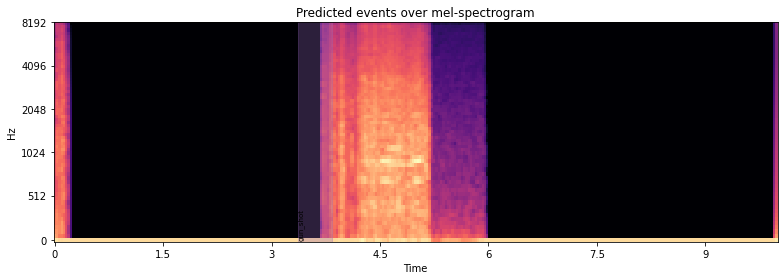

In [7]:
# spectrogram with predicted event spans overlaid
S = librosa.feature.melspectrogram(y=wav, sr=SR, n_mels=64)
SdB = librosa.power_to_db(S, ref=np.max)
plt.figure(figsize=(11, 4))
librosa.display.specshow(SdB, sr=SR, x_axis='time', y_axis='mel', cmap='magma')
colors = plt.cm.tab10(np.linspace(0, 1, len(TARGET_EVENTS)))
cmap = {ev: colors[i] for i, ev in enumerate(TARGET_EVENTS)}
for e in pred_events:
    plt.axvspan(e['onset'], e['offset'], color=cmap[e['event']], alpha=0.3)
    plt.text(e['onset'], 0, e['event'], fontsize=7, rotation=90, va='bottom')
plt.title('Predicted events over mel-spectrogram'); plt.tight_layout(); plt.show()
from IPython.display import Audio, display
display(Audio(wav, rate=SR))

## 6. Evaluate against strong labels
Two standard SED metrics, computed manually so nothing extra needs installing:
- **Segment-based F1** on a fixed 1 s grid (was each event active in each second?) — lenient.
- **Event-based F1**: a prediction counts only if its **onset** is within `COLLAR` of a
  reference event of the same label — strict on timing.

(For production use the `sed_eval` library, which also gives Error Rate and PSDS.)

In [8]:
ref_all = pd.read_csv(ANNOT_CSV)   # filename,onset,offset,event

def segment_f1(ref, pred, dur, res=1.0):
    nseg = int(np.ceil(dur / res))
    labels = TARGET_EVENTS
    def grid(ev_list):
        g = {ev: np.zeros(nseg, bool) for ev in labels}
        for e in ev_list:
            if e['event'] in g:
                a, b = int(e['onset']//res), int(np.ceil(e['offset']/res))
                g[e['event']][a:b] = True
        return g
    R, P = grid(ref), grid(pred)
    tp=fp=fn=0
    for ev in labels:
        tp += np.sum(R[ev] & P[ev]); fp += np.sum(~R[ev] & P[ev]); fn += np.sum(R[ev] & ~P[ev])
    prec = tp/(tp+fp) if tp+fp else 0; rec = tp/(tp+fn) if tp+fn else 0
    f1 = 2*prec*rec/(prec+rec) if prec+rec else 0
    return prec, rec, f1

def event_f1(ref, pred, collar=COLLAR):
    used = [False]*len(ref); tp=0
    for p in pred:
        for k, r in enumerate(ref):
            if (not used[k] and r['event']==p['event']
                    and abs(r['onset']-p['onset']) <= collar):
                used[k]=True; tp+=1; break
    fp=len(pred)-tp; fn=len(ref)-tp
    prec = tp/(tp+fp) if tp+fp else 0; rec = tp/(tp+fn) if tp+fn else 0
    f1 = 2*prec*rec/(prec+rec) if prec+rec else 0
    return prec, rec, f1

# aggregate over all clips in the subset
seg_scores, evt_scores = [], []
for f in wav_files:
    name = os.path.basename(f)
    w, _ = librosa.load(f, sr=SR, mono=True)
    dur = len(w)/SR
    preds, _ = detect(w)
    r = ref_all[ref_all['filename']==name]
    ref = [{'event':row['event'],'onset':row['onset'],'offset':row['offset']}
           for _, row in r.iterrows()]
    seg_scores.append(segment_f1(ref, preds, dur))
    evt_scores.append(event_f1(ref, preds))

seg = np.mean(seg_scores, axis=0); evt = np.mean(evt_scores, axis=0)
print(f'Segment-based  P={seg[0]:.2f}  R={seg[1]:.2f}  F1={seg[2]:.2f}')
print(f'Event-based    P={evt[0]:.2f}  R={evt[1]:.2f}  F1={evt[2]:.2f}  (collar={COLLAR}s)')

Segment-based  P=0.20  R=0.12  F1=0.14
Event-based    P=0.11  R=0.06  F1=0.07  (collar=0.5s)


## Summary
In this demo, you saw:
1. **Frozen-tagger SED**: per-frame scores -> threshold/smoothing -> (event, onset, offset)
2. **Evaluation**: segment-based F1 vs strict event-based F1
### Key Takeaways

- SED with a **frozen** tagger: per-frame scores + threshold + smoothing already give timed
  events — no training, but you must **map your events to AudioSet classes** (the `MAPPING` cell).
- **Segment-based F1 >> event-based F1** is expected: getting *when* roughly right is easy,
  getting exact onsets is hard. Always report the event-based number.
- Levers to tune live: `THRESHOLD` (precision/recall trade-off), `MEDIAN_K` (fragmentation vs
  merging), `COLLAR` (timing strictness).
- Trained CRNN / CNN-Transformer models (M-slides) beat this, but this shows the task end-to-end
  with zero training.